<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); padding: 40px; border-radius: 16px; text-align: center; margin-bottom: 24px; border: 1px solid #4361EE;">
  <h1 style="color: #FFFFFF; font-size: 2.2em; margin: 0 0 8px 0; font-family: 'Segoe UI', sans-serif;">🏛️ TRƯỜNG ĐẠI HỌC KINH TẾ QUỐC DÂN (NEU)</h1>
  <h2 style="color: #A8C6FA; font-size: 1.3em; margin: 0 0 20px 0; font-weight: 400;">Khoa Hệ thống Thông tin Kinh tế & Thương mại điện tử</h2>
  <hr style="border-color: #4361EE; margin: 16px 0;">
  <h2 style="color: #F72585; font-size: 1.5em; margin: 12px 0;">📚 BÀI TẬP GIỮA KỲ: MÔN HỌC MÁY (MACHINE LEARNING)</h2>
  <h3 style="color: #06D6A0; font-size: 1.3em; margin: 12px 0;">💳 DỰ ĐOÁN ĐIỂM TÍN DỤNG &amp; XÁC SUẤT VỠ NỢ THẺ TÍN DỤNG</h3>
  <h4 style="color: #FFD166; font-size: 1.1em; margin: 12px 0;">Credit Scoring &amp; Default Prediction Using Machine Learning</h4>
  <hr style="border-color: #4361EE; margin: 16px 0;">
  <table style="margin: auto; color: #FFFFFF; font-size: 1em;">
    <tr><td style="padding: 6px 20px; text-align: right; color: #A8C6FA;"><b>Nhóm:</b></td><td style="padding: 6px 20px;">Nhóm 4 | Lớp DS66B</td></tr>
    <tr><td style="padding: 6px 20px; text-align: right; color: #A8C6FA;"><b>Thành viên:</b></td><td style="padding: 6px 20px;">Nguyễn Bảo Khánh – MSV: <b>11247178</b></td></tr>
    <tr><td style="padding: 6px 20px; text-align: right;"></td><td style="padding: 6px 20px;">Nguyễn Phạm Tuân – MSV: <b>11247242</b></td></tr>
    <tr><td style="padding: 6px 20px; text-align: right; color: #A8C6FA;"><b>Dữ liệu:</b></td><td style="padding: 6px 20px;">UCI Credit Card Dataset (30,000 mẫu)</td></tr>
    <tr><td style="padding: 6px 20px; text-align: right; color: #A8C6FA;"><b>Năm học:</b></td><td style="padding: 6px 20px;">2025 – 2026</td></tr>
  </table>
</div>

## 📋 Mục lục

| # | Phần | Nội dung |
|---|------|----------|
| 0 | **Cấu hình & Imports** | Autoreload, thư viện, modules src |
| 1 | **EDA & Khám phá dữ liệu** | Kiểm tra chất lượng, phân phối, tương quan |
| 2 | **Feature Engineering** | Tạo biến RFM & chỉ số tài chính tín dụng |
| 3 | **Tiền xử lý & Huấn luyện** | Preprocessing, Cross-Validation 5-Fold |
| 4 | **Đánh giá & So sánh mô hình** | Test set metrics, ROC/PR curves, Confusion Matrix |
| 5 | **Hệ thống Chấm điểm FICO** | Scorecard, phân hạng, demo khách hàng |
| 6 | **Kết luận & Kiến nghị** | Tổng kết, khuyến nghị ngân hàng |

---
## ⚙️ Phần 0: Cấu hình & Import Thư viện

In [1]:
# ============================================================
# Tự động reload modules khi chỉnh sửa file trong src/
# ============================================================
%load_ext autoreload
%autoreload 2

In [2]:
# ============================================================
# THƯ VIỆN CHUẨN
# ============================================================
import os
import sys
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

# Thêm thư mục gốc vào sys.path để import src/
sys.path.insert(0, os.path.abspath('.'))

# ============================================================
# IMPORT CÁC MODULE TỪ src/
# ============================================================
from src.data_loader import load_data, check_data_quality, get_target_distribution
from src.preprocessing import clean_raw_data, split_data, get_preprocessor, get_feature_columns
from src.feature_engineering import build_features, get_engineered_feature_names
from src.visualization import (
    plot_target_distribution,
    plot_correlation_heatmap,
    plot_delinquency_vs_default,
    plot_feature_importance,
)
from src.models import get_baseline_models, train_cross_validation, tune_xgboost_lightgbm
from src.evaluation import (
    evaluate_all_models,
    plot_roc_and_pr_curves,
    plot_confusion_matrices,
    print_classification_report,
)
from src.credit_scoring import (
    prob_to_fico_score,
    get_credit_rating,
    score_new_customer,
    batch_score_customers,
)

# Sklearn cho Pipeline
from sklearn.pipeline import Pipeline

print('✅ Tất cả thư viện và modules đã được import thành công!')
print(f'   NumPy: {np.__version__}  |  Pandas: {pd.__version__}')

# Đường dẫn dữ liệu
DATA_PATH = 'data/UCI_Credit_Card.csv'
TARGET_COL = 'default.payment.next.month'

✅ Tất cả thư viện và modules đã được import thành công!
   NumPy: 2.5.2  |  Pandas: 3.0.5


---
## 📊 Phần 1: EDA & Khám phá Dữ liệu (Exploratory Data Analysis)

> **Mục tiêu:** Hiểu cấu trúc dữ liệu, phân phối biến mục tiêu, kiểm tra chất lượng và phân tích tương quan giữa các đặc trưng.

### Thông tin tập dữ liệu UCI Credit Card
| Thuộc tính | Chi tiết |
|---|---|
| Số mẫu | 30,000 khách hàng thẻ tín dụng |
| Số cột | 25 (gồm 1 biến mục tiêu) |
| Biến mục tiêu | `default.payment.next.month` (0/1) |
| Mất cân bằng | 22.12% vỡ nợ vs 77.88% không vỡ nợ |

In [3]:
# ============================================================
# 1.1 Nạp dữ liệu
# ============================================================
df_raw = load_data(DATA_PATH)
df_raw.head(5)

📂 Đang nạp dữ liệu từ: data/UCI_Credit_Card.csv
✅ Nạp thành công! Kích thước: 30,000 dòng × 25 cột


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0000,2,2,1,24,2,2,-1,-1,-2,-2,3913.0000,3102.0000,689.0000,0.0000,0.0000,0.0000,0.0000,689.0000,0.0000,0.0000,0.0000,0.0000,1
1,2,120000.0000,2,2,2,26,-1,2,0,0,0,2,2682.0000,1725.0000,2682.0000,3272.0000,3455.0000,3261.0000,0.0000,1000.0000,1000.0000,1000.0000,0.0000,2000.0000,1
2,3,90000.0000,2,2,2,34,0,0,0,0,0,0,29239.0000,14027.0000,13559.0000,14331.0000,14948.0000,15549.0000,1518.0000,1500.0000,1000.0000,1000.0000,1000.0000,5000.0000,0
3,4,50000.0000,2,2,1,37,0,0,0,0,0,0,46990.0000,48233.0000,49291.0000,28314.0000,28959.0000,29547.0000,2000.0000,2019.0000,1200.0000,1100.0000,1069.0000,1000.0000,0
4,5,50000.0000,1,2,1,57,-1,0,-1,0,0,0,8617.0000,5670.0000,35835.0000,20940.0000,19146.0000,19131.0000,2000.0000,36681.0000,10000.0000,9000.0000,689.0000,679.0000,0


In [4]:
# ============================================================
# 1.2 Kiểm tra chất lượng dữ liệu
# ============================================================
missing_summary = check_data_quality(df_raw)


📊 KIỂM TRA CHẤT LƯỢNG DỮ LIỆU

🔢 Kích thước dữ liệu: 30,000 dòng × 25 cột

✅ Không có missing values!

✅ Không có hàng trùng lặp (duplicates)!

📋 Kiểu dữ liệu từng cột:
   float64: 13 cột
   int64: 12 cột

📈 Thống kê cơ bản (numeric):
              ID    LIMIT_BAL        SEX  EDUCATION   MARRIAGE        AGE      PAY_0      PAY_2      PAY_3      PAY_4      PAY_5      PAY_6    BILL_AMT1   BILL_AMT2    BILL_AMT3    BILL_AMT4   BILL_AMT5    BILL_AMT6    PAY_AMT1     PAY_AMT2    PAY_AMT3    PAY_AMT4    PAY_AMT5    PAY_AMT6  default.payment.next.month
count 30000.0000   30000.0000 30000.0000 30000.0000 30000.0000 30000.0000 30000.0000 30000.0000 30000.0000 30000.0000 30000.0000 30000.0000   30000.0000  30000.0000   30000.0000   30000.0000  30000.0000   30000.0000  30000.0000   30000.0000  30000.0000  30000.0000  30000.0000  30000.0000                  30000.0000
mean  15000.5000  167484.3200     1.6000     1.8500     1.5500    35.4900    -0.0200    -0.1300    -0.1700    -0.2200    -0.2700  


📊 Phân phối biến mục tiêu: 'default.payment.next.month'
               Nhãn  Số lượng  Tỉ lệ (%)
    0 - Không vỡ nợ     23364    77.8800
1 - Vỡ nợ (Default)      6636    22.1200

📌 Tỉ lệ mất cân bằng lớp: 22.12% positive class (vỡ nợ)


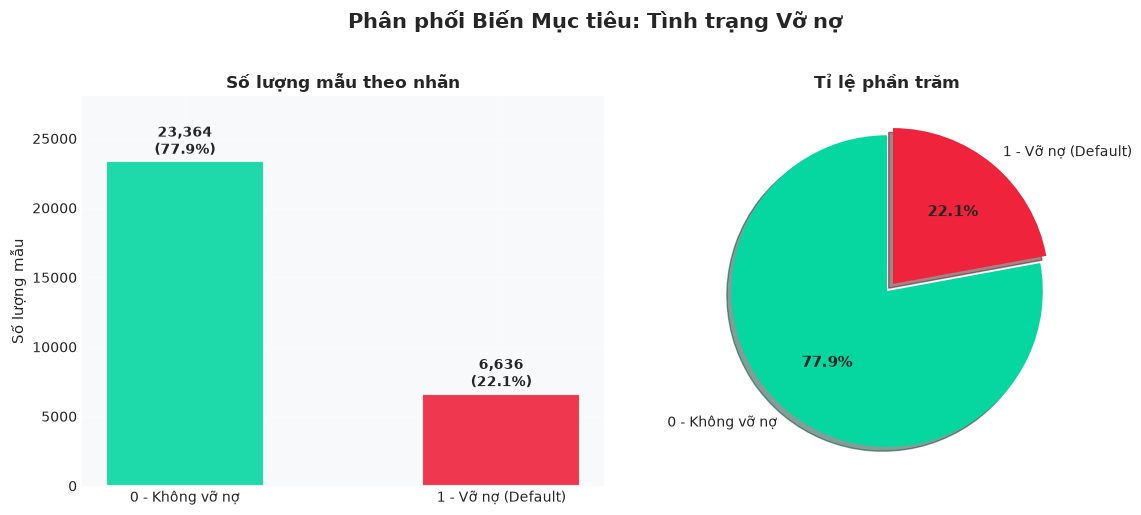

📊 Tỉ lệ mất cân bằng: 77.9% (0) vs 22.1% (1)


In [5]:
# ============================================================
# 1.3 Phân phối biến mục tiêu
# ============================================================
dist_df = get_target_distribution(df_raw, TARGET_COL)
plot_target_distribution(df_raw, TARGET_COL)

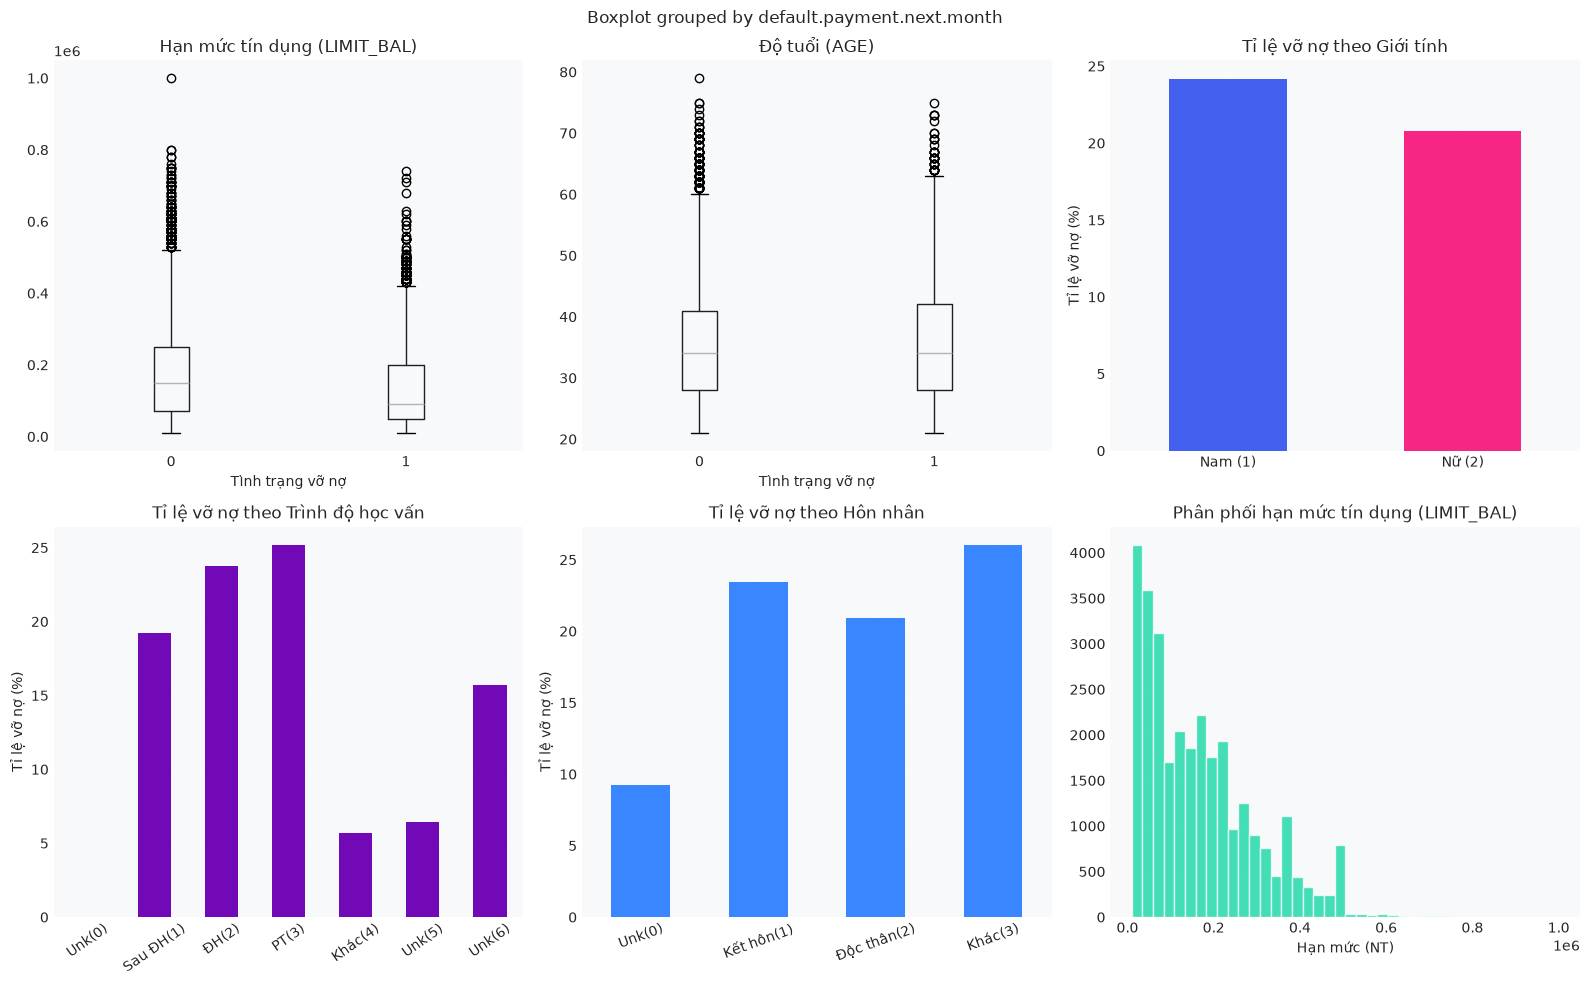

In [6]:
# ============================================================
# 1.4 Phân tích nhân khẩu học
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Phân tích Nhân khẩu học theo Tình trạng Vỡ nợ', fontsize=14, fontweight='bold')

# LIMIT_BAL
df_raw.boxplot(column='LIMIT_BAL', by=TARGET_COL, ax=axes[0,0], grid=False)
axes[0,0].set_title('Hạn mức tín dụng (LIMIT_BAL)')
axes[0,0].set_xlabel('Tình trạng vỡ nợ')

# AGE
df_raw.boxplot(column='AGE', by=TARGET_COL, ax=axes[0,1], grid=False)
axes[0,1].set_title('Độ tuổi (AGE)')
axes[0,1].set_xlabel('Tình trạng vỡ nợ')

# SEX
sex_default = df_raw.groupby('SEX')[TARGET_COL].mean() * 100
sex_default.index = ['Nam (1)', 'Nữ (2)']
sex_default.plot(kind='bar', ax=axes[0,2], color=['#4361EE', '#F72585'], rot=0)
axes[0,2].set_title('Tỉ lệ vỡ nợ theo Giới tính')
axes[0,2].set_ylabel('Tỉ lệ vỡ nợ (%)')

# EDUCATION (raw has 7 values: 0,1,2,3,4,5,6)
edu_default = df_raw.groupby('EDUCATION')[TARGET_COL].mean() * 100
edu_labels = {0: 'Unk(0)', 1: 'Sau ĐH(1)', 2: 'ĐH(2)', 3: 'PT(3)', 4: 'Khác(4)', 5: 'Unk(5)', 6: 'Unk(6)'}
edu_default.index = [edu_labels.get(i, str(i)) for i in edu_default.index]
edu_default.plot(kind='bar', ax=axes[1,0], color='#7209B7', rot=35)
axes[1,0].set_title('Tỉ lệ vỡ nợ theo Trình độ học vấn')
axes[1,0].set_ylabel('Tỉ lệ vỡ nợ (%)')

# MARRIAGE (raw has 4 values: 0,1,2,3)
mar_default = df_raw.groupby('MARRIAGE')[TARGET_COL].mean() * 100
mar_labels = {0: 'Unk(0)', 1: 'Kết hôn(1)', 2: 'Độc thân(2)', 3: 'Khác(3)'}
mar_default.index = [mar_labels.get(i, str(i)) for i in mar_default.index]
mar_default.plot(kind='bar', ax=axes[1,1], color='#3A86FF', rot=20)
axes[1,1].set_title('Tỉ lệ vỡ nợ theo Hôn nhân')
axes[1,1].set_ylabel('Tỉ lệ vỡ nợ (%)')

# LIMIT_BAL distribution
df_raw['LIMIT_BAL'].hist(ax=axes[1,2], bins=40, color='#06D6A0', alpha=0.75, edgecolor='white')
axes[1,2].set_title('Phân phối hạn mức tín dụng (LIMIT_BAL)')
axes[1,2].set_xlabel('Hạn mức (NT)')

plt.tight_layout()
plt.show()

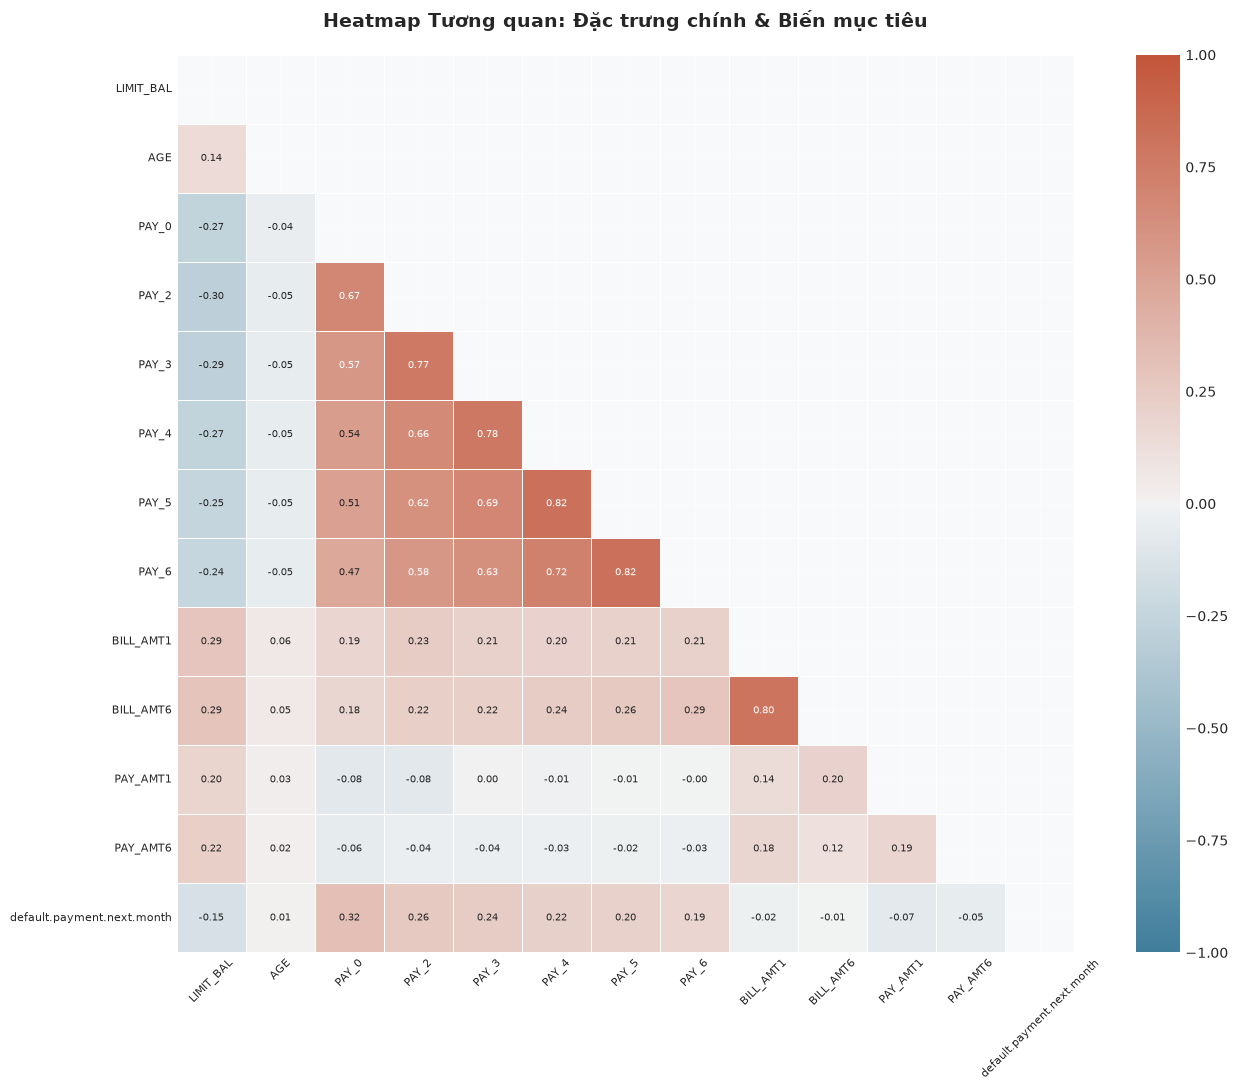

In [7]:
# ============================================================
# 1.5 Heatmap tương quan (biến chính)
# ============================================================
key_cols = [
    'LIMIT_BAL', 'AGE',
    'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT6',
    TARGET_COL
]
plot_correlation_heatmap(
    df_raw, cols=key_cols,
    title='Heatmap Tương quan: Đặc trưng chính & Biến mục tiêu'
)

---
## 🔧 Phần 2: Feature Engineering (Tạo biến RFM & Chỉ số Tài chính)

> **Mục tiêu:** Áp dụng tư duy RFM (Recency–Frequency–Monetary) trong tín dụng để tạo ra các đặc trưng mới có khả năng phân biệt tốt hơn giữa khách hàng vỡ nợ và không vỡ nợ.

| Nhóm | Biến | Ý nghĩa nghiệp vụ |
|------|------|-------------------|
| **R - Recency** | `r_weighted_delay` | Trọng số thời gian trễ (T9×6...T4×1) |
| **R - Recency** | `r_delay_trend` | Xu hướng trễ hạn (PAY_0 – PAY_6) |
| **R - Recency** | `r_recent_delay` | Mức trễ tháng gần nhất |
| **F - Frequency** | `f_total_delay_months` | Tổng tháng trễ hạn (6 tháng) |
| **F - Frequency** | `f_max_delay` | Mức trễ tối đa từng ghi nhận |
| **F - Frequency** | `f_full_pay_months` | Số tháng trả đủ đúng hạn |
| **F - Frequency** | `f_consecutive_delay` | Cờ trễ liên tiếp 2 tháng gần nhất |
| **M - Monetary** | `m_total_bill_amt` | Tổng dư nợ sao kê 6 tháng |
| **M - Monetary** | `m_total_pay_amt` | Tổng số tiền đã thanh toán |
| **M - Monetary** | `m_net_debt` | Dư nợ ròng còn lại |
| **M - Monetary** | `m_avg_utilization` | Tỉ lệ sử dụng hạn mức trung bình |
| **M - Monetary** | `m_repayment_ratio` | Tỉ lệ trả nợ / dư nợ |
| **M - Monetary** | `m_bill_growth` | Tốc độ tăng trưởng dư nợ |

In [8]:
# ============================================================
# 2.1 Làm sạch dữ liệu thô
# ============================================================
df_clean = clean_raw_data(df_raw)
print(f'\n📋 Kiểm tra EDUCATION sau làm sạch: {sorted(df_clean["EDUCATION"].unique())}')
print(f'📋 Kiểm tra MARRIAGE sau làm sạch:  {sorted(df_clean["MARRIAGE"].unique())}')

✅ Đã loại bỏ cột 'ID'.
✅ EDUCATION: gom 468 giá trị dị biệt {0,4,5,6} → 4 (Khác).
✅ MARRIAGE: gom 377 giá trị dị biệt {0,3} → 3 (Khác).
✅ Dữ liệu sau làm sạch: 30,000 dòng × 24 cột.

📋 Kiểm tra EDUCATION sau làm sạch: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
📋 Kiểm tra MARRIAGE sau làm sạch:  [np.int64(1), np.int64(2), np.int64(3)]


In [9]:
# ============================================================
# 2.2 Tạo biến RFM & chỉ số tài chính
# ============================================================
df_features = build_features(df_clean)

# Xem các biến mới
new_feature_names = get_engineered_feature_names()
print('\n📊 Thống kê các biến RFM mới tạo:')
df_features[new_feature_names].describe().round(3)

✅ Feature Engineering hoàn tất: +13 biến RFM & tài chính mới.
   Tổng số cột sau engineering: 37

📊 Thống kê các biến RFM mới tạo:


,r_weighted_delay,r_delay_trend,r_recent_delay,f_total_delay_months,f_max_delay,f_full_pay_months,f_consecutive_delay,m_total_bill_amt,m_total_pay_amt,m_net_debt,m_avg_utilization,m_repayment_ratio,m_bill_growth
count,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000
mean,6.4030,0.2740,-0.0170,0.8340,0.4390,1.9680,0.1330,269861.6710,31651.3930,238210.2790,0.3730,21.0400,0.1050
std,13.1160,1.1660,1.1240,1.5540,1.3450,2.4520,0.3400,379564.3310,60827.6780,363165.0630,0.3500,1255.7710,0.3010
min,0.0000,-7.0000,-2.0000,0.0000,-2.0000,0.0000,0.0000,-336259.0000,0.0000,-2671514.0000,0.0000,-589.0000,-1.8270
25%,0.0000,0.0000,-1.0000,0.0000,0.0000,0.0000,0.0000,28688.0000,6679.7500,4520.7500,0.0300,0.0410,-0.0290
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,126311.0000,14383.0000,101923.0000,0.2850,0.0860,0.0070
75%,6.0000,1.0000,0.0000,1.0000,2.0000,5.0000,0.0000,342626.5000,33503.5000,305717.7500,0.6880,0.5980,0.1810
max,133.0000,7.0000,8.0000,6.0000,8.0000,6.0000,1.0000,5263883.0000,3764066.0000,4116080.0000,2.0000,162000.0000,5.3100


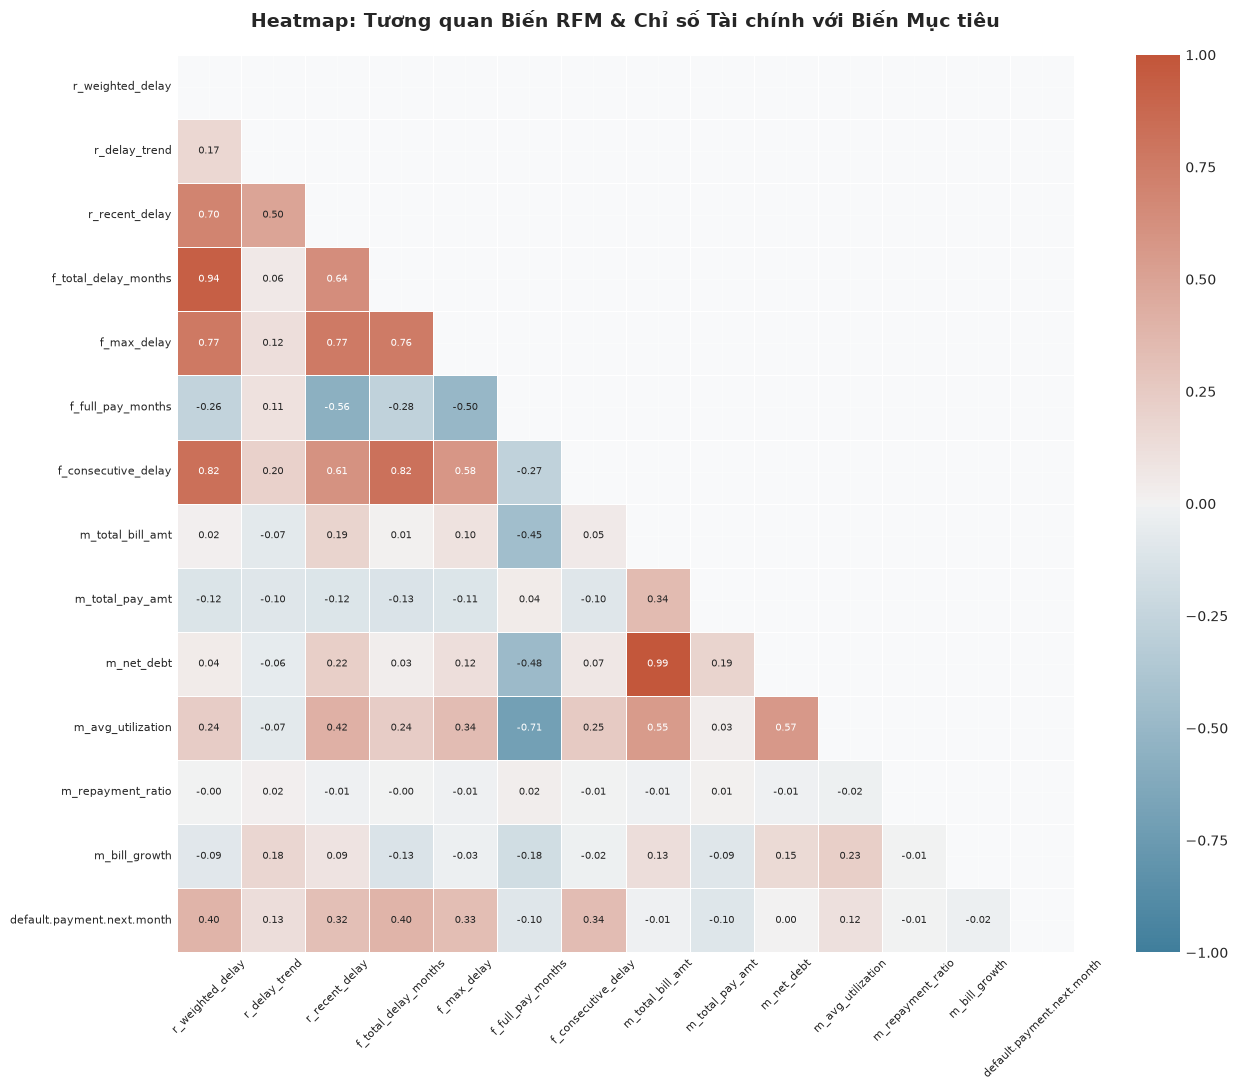

In [10]:
# ============================================================
# 2.3 Heatmap tương quan biến RFM với biến mục tiêu
# ============================================================
rfm_cols = new_feature_names + [TARGET_COL]
plot_correlation_heatmap(
    df_features, cols=rfm_cols,
    title='Heatmap: Tương quan Biến RFM & Chỉ số Tài chính với Biến Mục tiêu'
)

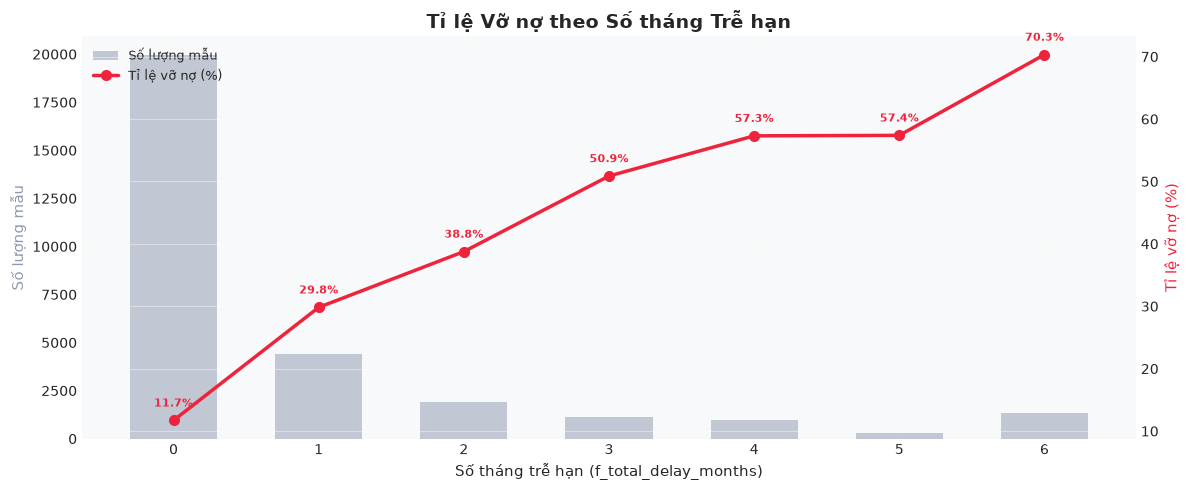

In [11]:
# ============================================================
# 2.4 Tỉ lệ vỡ nợ theo số tháng trễ hạn
# ============================================================
plot_delinquency_vs_default(df_features, TARGET_COL)

---
## 🏋️ Phần 3: Tiền xử lý & Huấn luyện Mô hình (5-Fold Cross-Validation)

> **Mục tiêu:** Xây dựng pipeline tiền xử lý không rò rỉ dữ liệu, huấn luyện 5 mô hình baseline và so sánh hiệu năng qua 5-Fold Stratified Cross-Validation.

**Pipeline tiền xử lý:**
- ✅ Chia train/test TRƯỚC khi fit preprocessor (No Data Leakage)
- ✅ `RobustScaler` cho biến số (ít nhạy với outliers)
- ✅ `OneHotEncoder` cho biến phân loại (SEX, EDUCATION, MARRIAGE)
- ✅ `class_weight='balanced'` / `scale_pos_weight` để xử lý mất cân bằng lớp

In [12]:
# ============================================================
# 3.1 Chia tập train/test (Stratified)
# ============================================================
X_train, X_test, y_train, y_test = split_data(
    df_features, target_col=TARGET_COL, test_size=0.2, random_state=42
)
print(f'\nKích thước:')
print(f'  X_train: {X_train.shape}  |  X_test: {X_test.shape}')
print(f'  y_train: {y_train.shape}  |  y_test: {y_test.shape}')


✅ Chia tập dữ liệu (stratified, test_size=0.2):
   Train: 24,000 mẫu  |  Test: 6,000 mẫu
   Tỉ lệ vỡ nợ Train: 0.2212  |  Test: 0.2212

Kích thước:
  X_train: (24000, 36)  |  X_test: (6000, 36)
  y_train: (24000,)  |  y_test: (6000,)


In [13]:
# ============================================================
# 3.2 Xây dựng preprocessor & pipeline
# ============================================================
numeric_cols, categorical_cols = get_feature_columns(df_features, TARGET_COL)
print(f'Numeric features  ({len(numeric_cols)}): {numeric_cols[:8]}...')
print(f'Category features ({len(categorical_cols)}): {categorical_cols}')

preprocessor = get_preprocessor(numeric_cols, categorical_cols)

Numeric features  (33): ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']...
Category features (3): ['SEX', 'EDUCATION', 'MARRIAGE']
✅ Preprocessor đã tạo:
   Numeric  (33 cột): RobustScaler
   Category (3 cột): OneHotEncoder


In [14]:
# ============================================================
# 3.3 Fit preprocessor CHỈ trên train (tránh Data Leakage)
#     Transform cả train và test
# ============================================================
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

print(f'\n✅ Sau tiền xử lý:')
print(f'   X_train_processed: {X_train_processed.shape}')
print(f'   X_test_processed:  {X_test_processed.shape}')


✅ Sau tiền xử lý:
   X_train_processed: (24000, 42)
   X_test_processed:  (6000, 42)


In [15]:
# ============================================================
# 3.4 Khởi tạo 5 mô hình baseline
# ============================================================
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_w = neg_count / pos_count
print(f'scale_pos_weight (XGBoost): {scale_pos_w:.4f}')

baseline_models = get_baseline_models(scale_pos_weight=scale_pos_w)

scale_pos_weight (XGBoost): 3.5206
✅ Đã khởi tạo 5 mô hình baseline.


In [16]:
# ============================================================
# 3.5 5-Fold Stratified Cross-Validation
#     (Chạy trên X_train_processed để đánh giá ổn định)
# ============================================================
cv_results = train_cross_validation(
    baseline_models,
    X_train_processed,
    y_train.values,
    cv=5
)
cv_results


🔄 STRATIFIED 5-FOLD CROSS-VALIDATION

⏳ Đang CV: Logistic Regression...
   ✅ Logistic Regression: ROC-AUC = 0.7656 ± 0.0068  |  F1 = 0.5293 ± 0.0104

⏳ Đang CV: Random Forest...
   ✅ Random Forest: ROC-AUC = 0.7856 ± 0.0051  |  F1 = 0.5425 ± 0.0071

⏳ Đang CV: Gradient Boosting...
   ✅ Gradient Boosting: ROC-AUC = 0.7854 ± 0.0068  |  F1 = 0.4826 ± 0.0072

⏳ Đang CV: XGBoost...
   ✅ XGBoost: ROC-AUC = 0.7864 ± 0.0069  |  F1 = 0.5426 ± 0.0089

⏳ Đang CV: LightGBM...
   ✅ LightGBM: ROC-AUC = 0.7806 ± 0.0084  |  F1 = 0.5369 ± 0.0091

📊 BẢNG TỔNG HỢP CV SCORES:
                     ROC_AUC Mean  ROC_AUC Std  F1 Mean  F1 Std  PRECISION Mean  RECALL Mean
Model                                                                                       
Logistic Regression        0.7656       0.0068   0.5293  0.0104          0.4622       0.6193
Random Forest              0.7856       0.0051   0.5425  0.0071          0.4913       0.6058
Gradient Boosting          0.7854       0.0068   0.4826  0.0072 

,ROC_AUC Mean,ROC_AUC Std,F1 Mean,F1 Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std
Model,,,,,,,,
Logistic Regression,0.7656,0.0068,0.5293,0.0104,0.4622,0.0115,0.6193,0.0105
Random Forest,0.7856,0.0051,0.5425,0.0071,0.4913,0.0117,0.6058,0.0020
Gradient Boosting,0.7854,0.0068,0.4826,0.0072,0.6714,0.0202,0.3767,0.0037
XGBoost,0.7864,0.0069,0.5426,0.0089,0.4716,0.0096,0.6389,0.0086
LightGBM,0.7806,0.0084,0.5369,0.0091,0.4709,0.0103,0.6246,0.0069


In [17]:
# ============================================================
# 3.6 Fit tất cả mô hình trên toàn bộ tập train
# ============================================================
fitted_models = {}
for name, model in baseline_models.items():
    model.fit(X_train_processed, y_train)
    fitted_models[name] = model
    print(f'✅ Đã huấn luyện: {name}')

print(f'\n🎉 Hoàn tất huấn luyện {len(fitted_models)} mô hình!')

✅ Đã huấn luyện: Logistic Regression
✅ Đã huấn luyện: Random Forest
✅ Đã huấn luyện: Gradient Boosting
✅ Đã huấn luyện: XGBoost
✅ Đã huấn luyện: LightGBM

🎉 Hoàn tất huấn luyện 5 mô hình!


In [ ]:
# ============================================================
# 3.7 Hyperparameter Tuning - LightGBM
# ============================================================
best_lgbm, lgbm_best_params = tune_xgboost_lightgbm(
    X_train_processed, y_train.values,
    model_name='LightGBM',
    n_iter=20,
    cv=5
)

# Thêm vào fitted_models
fitted_models['LightGBM (Tuned)'] = best_lgbm
print('\n✅ Đã bổ sung LightGBM (Tuned) vào danh sách mô hình.')


🔧 Hyperparameter Tuning: LightGBM (n_iter=20, cv=5)
   ⏳ Đang tìm kiếm tham số tốt nhất... (có thể mất vài phút)

✅ Kết quả Tuning LightGBM:
   Best CV ROC-AUC: 0.7860
   Best Params:
     colsample_bytree: 1.0
     learning_rate: 0.05
     max_depth: 4
     n_estimators: 100
     num_leaves: 63
     reg_alpha: 0.5
     reg_lambda: 0.01
     subsample: 0.7

✅ Đã bổ sung LightGBM (Tuned) vào danh sách mô hình.


---
## 📈 Phần 4: Đánh giá & So sánh Mô hình trên Tập Test

> **Mục tiêu:** Đánh giá toàn diện hiệu năng thực tế của các mô hình trên tập test chưa thấy, sử dụng nhiều metrics phù hợp với bài toán mất cân bằng lớp.

**Các chỉ số đánh giá:**
- **ROC-AUC**: Diện tích dưới đường cong ROC – đo lường khả năng phân biệt tổng thể.
- **Gini Index = 2×AUC – 1**: Chỉ số phổ biến trong credit scoring.
- **PR-AUC**: Precision-Recall AUC – quan trọng khi dữ liệu mất cân bằng.
- **F1-Score**: Cân bằng Precision và Recall.
- **Recall**: Tỉ lệ phát hiện đúng các trường hợp vỡ nợ (critical!).

In [19]:
# ============================================================
# 4.1 Bảng tổng hợp metrics trên test set
# ============================================================
eval_results = evaluate_all_models(
    fitted_models,
    X_test_processed,
    y_test.values
)
eval_results


📊 ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST (threshold=0.5)

✅ Logistic Regression:
   Accuracy=0.7508 | Precision=0.4521 | Recall=0.5976 | F1=0.5148
   ROC-AUC=0.7544 | Gini=0.5087 | PR-AUC=0.5072

✅ Random Forest:
   Accuracy=0.7735 | Precision=0.4902 | Recall=0.6014 | F1=0.5401
   ROC-AUC=0.7787 | Gini=0.5574 | PR-AUC=0.5568

✅ Gradient Boosting:
   Accuracy=0.8182 | Precision=0.6532 | Recall=0.3791 | F1=0.4797
   ROC-AUC=0.7814 | Gini=0.5627 | PR-AUC=0.5546

✅ XGBoost:
   Accuracy=0.7597 | Precision=0.4680 | Recall=0.6330 | F1=0.5381
   ROC-AUC=0.7828 | Gini=0.5657 | PR-AUC=0.5642

✅ LightGBM:
   Accuracy=0.7578 | Precision=0.4645 | Recall=0.6209 | F1=0.5314
   ROC-AUC=0.7753 | Gini=0.5505 | PR-AUC=0.5550

✅ LightGBM (Tuned):
   Accuracy=0.7605 | Precision=0.4691 | Recall=0.6292 | F1=0.5375
   ROC-AUC=0.7821 | Gini=0.5641 | PR-AUC=0.5584

📋 BẢNG TỔNG HỢP KẾT QUẢ:
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC  Gini Index  PR-AUC
Model                                     

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Gini Index,PR-AUC
Model,,,,,,,
Logistic Regression,0.7508,0.4521,0.5976,0.5148,0.7544,0.5087,0.5072
Random Forest,0.7735,0.4902,0.6014,0.5401,0.7787,0.5574,0.5568
Gradient Boosting,0.8182,0.6532,0.3791,0.4797,0.7814,0.5627,0.5546
XGBoost,0.7597,0.4680,0.6330,0.5381,0.7828,0.5657,0.5642
LightGBM,0.7578,0.4645,0.6209,0.5314,0.7753,0.5505,0.5550
LightGBM (Tuned),0.7605,0.4691,0.6292,0.5375,0.7821,0.5641,0.5584


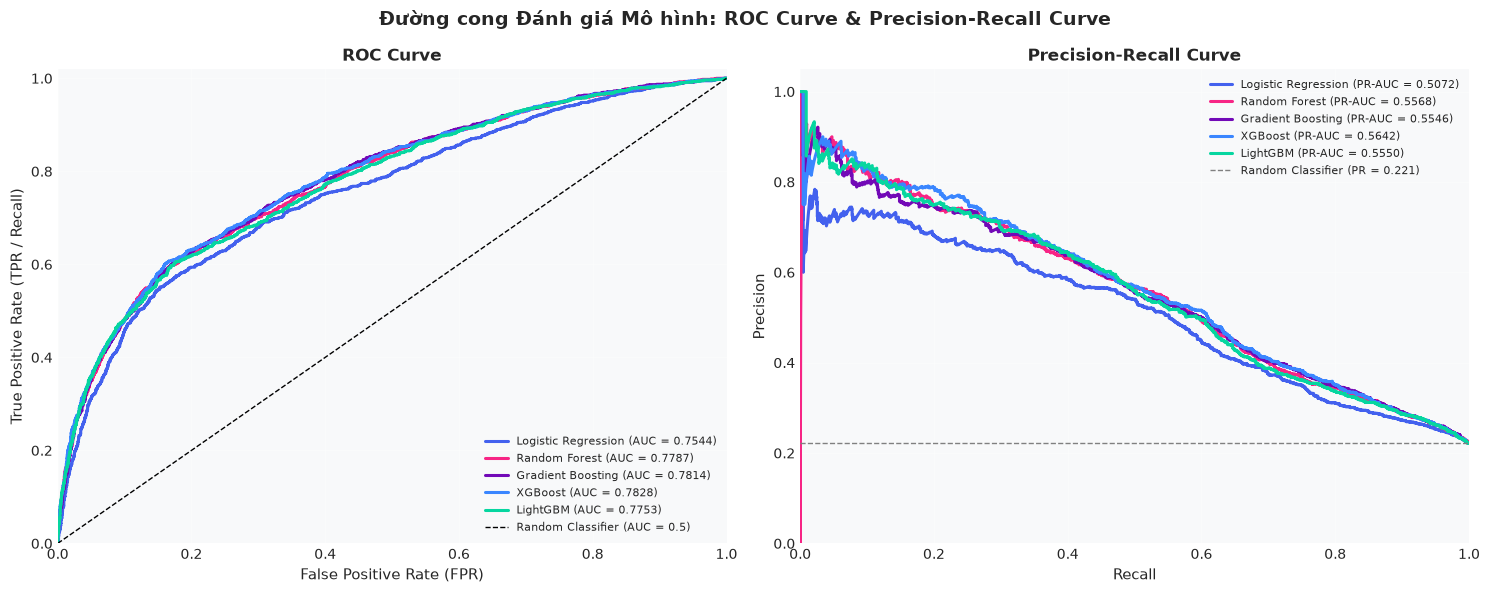

In [20]:
# ============================================================
# 4.2 ROC Curve & Precision-Recall Curve
# ============================================================
plot_roc_and_pr_curves(fitted_models, X_test_processed, y_test.values)

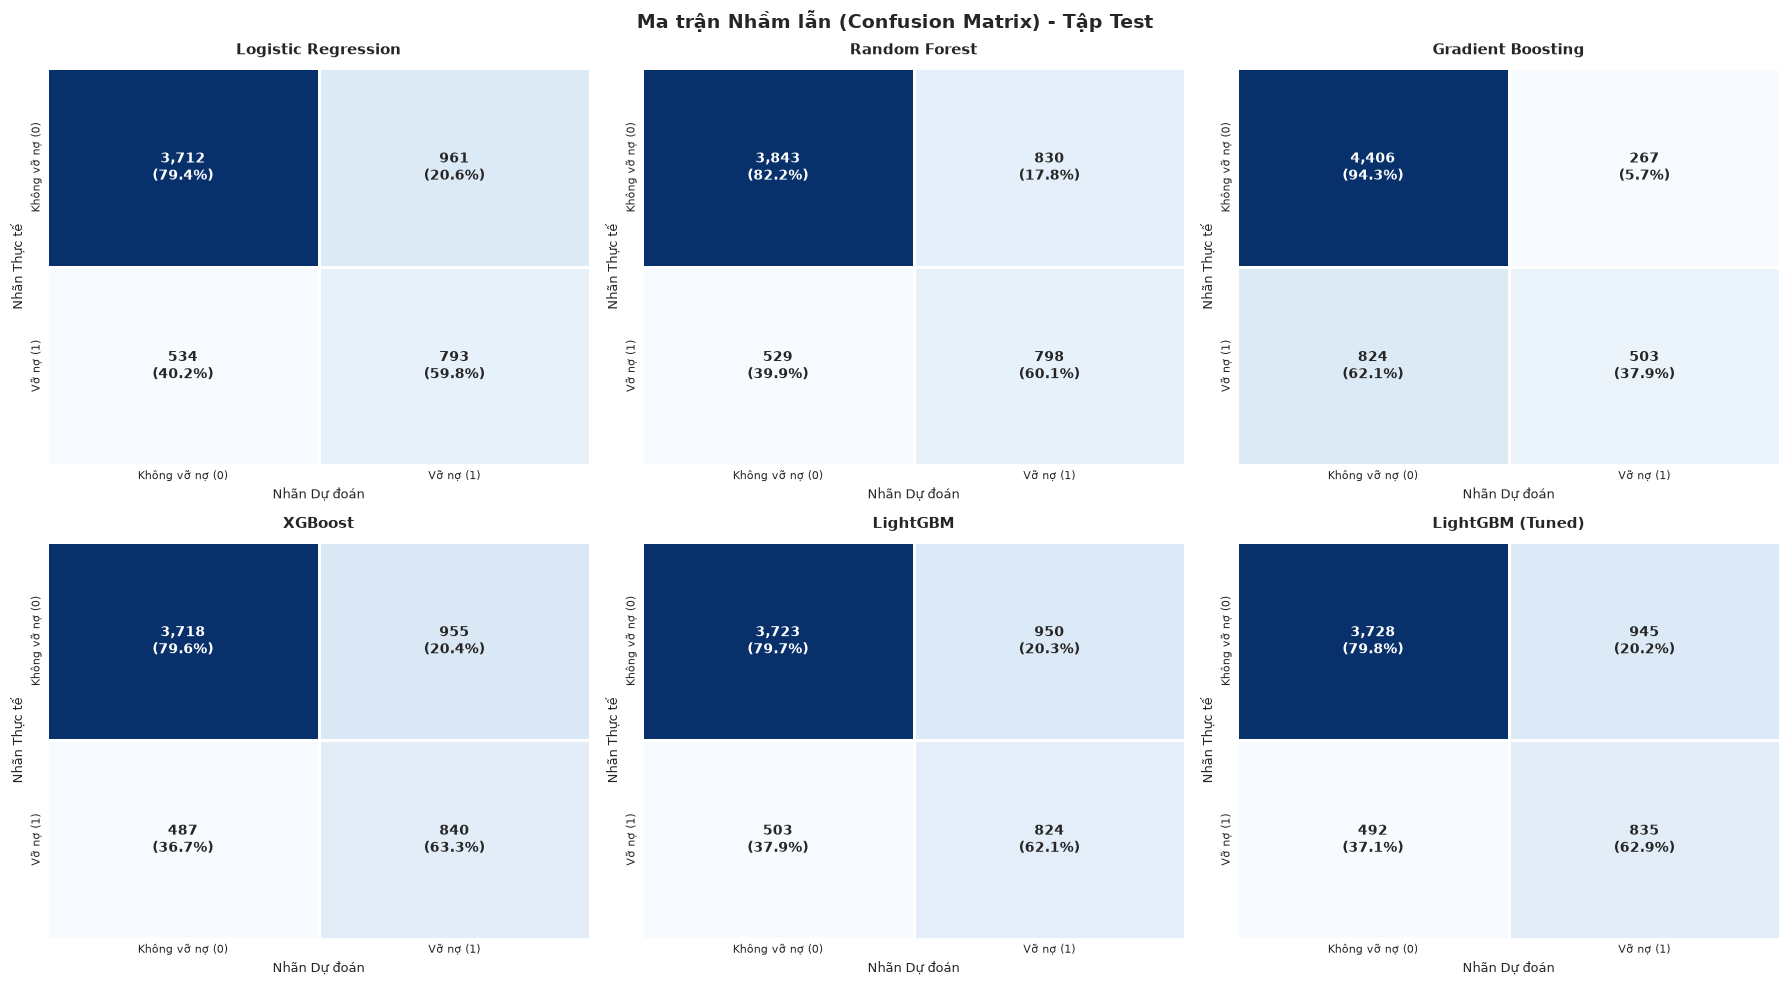

In [21]:
# ============================================================
# 4.3 Ma trận nhầm lẫn (Confusion Matrices)
# ============================================================
plot_confusion_matrices(fitted_models, X_test_processed, y_test.values)

🏆 Mô hình tốt nhất: XGBoost


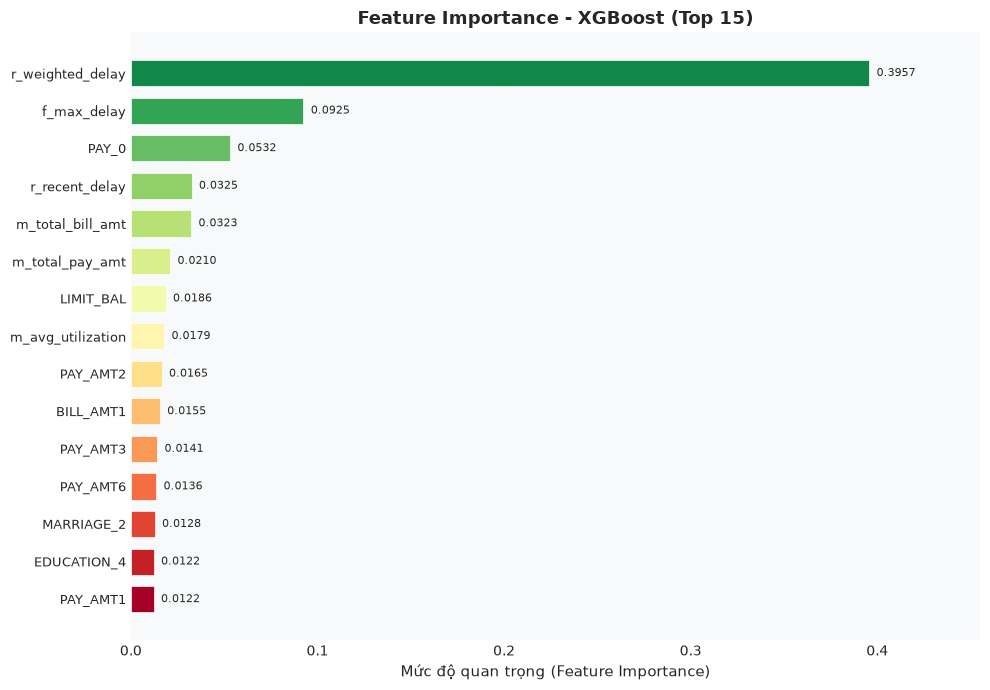

In [22]:
# ============================================================
# 4.4 Feature Importance (mô hình tốt nhất - LightGBM)
# ============================================================
# Lấy tên feature sau khi qua ColumnTransformer
try:
    feature_names_out = preprocessor.get_feature_names_out().tolist()
except Exception:
    feature_names_out = [f'feature_{i}' for i in range(X_train_processed.shape[1])]

best_model_name = eval_results['ROC-AUC'].idxmax()
best_model = fitted_models[best_model_name]
print(f'🏆 Mô hình tốt nhất: {best_model_name}')

plot_feature_importance(
    best_model,
    feature_names=feature_names_out,
    top_n=15,
    title=f'Feature Importance - {best_model_name}'
)

In [23]:
# ============================================================
# 4.5 Báo cáo phân loại chi tiết
# ============================================================
print_classification_report(
    {best_model_name: best_model},
    X_test_processed,
    y_test.values
)


📋 Classification Report: XGBoost
                 precision    recall  f1-score   support

Không vỡ nợ (0)       0.88      0.80      0.84      4673
      Vỡ nợ (1)       0.47      0.63      0.54      1327

       accuracy                           0.76      6000
      macro avg       0.68      0.71      0.69      6000
   weighted avg       0.79      0.76      0.77      6000



---
## 💳 Phần 5: Triển khai Hệ thống Chấm điểm Tín dụng (FICO Scorecard)

> **Mục tiêu:** Chuyển đổi xác suất vỡ nợ (PD) thành điểm tín dụng FICO tiêu chuẩn và phân hạng khuyến nghị cho bộ phận thẩm định tín dụng ngân hàng.

### Công thức quy đổi điểm FICO:
$$\text{Score} = 850 - (\text{PD} \times 550)$$

### Thang phân hạng tín dụng:
| Điểm | Hạng | Rủi ro | Khuyến nghị |
|------|------|--------|-------------|
| 750 – 850 | ⭐⭐⭐⭐⭐ Xuất sắc | Rất thấp | Duyệt ngay, ưu đãi lãi suất |
| 670 – 749 | ⭐⭐⭐⭐ Tốt | Thấp | Duyệt tiêu chuẩn |
| 580 – 669 | ⭐⭐⭐ Trung bình | Trung bình | Hạn mức thấp, giám sát nợ |
| 300 – 579 | ⭐⭐ Kém | Cao | Từ chối cấp tín dụng |

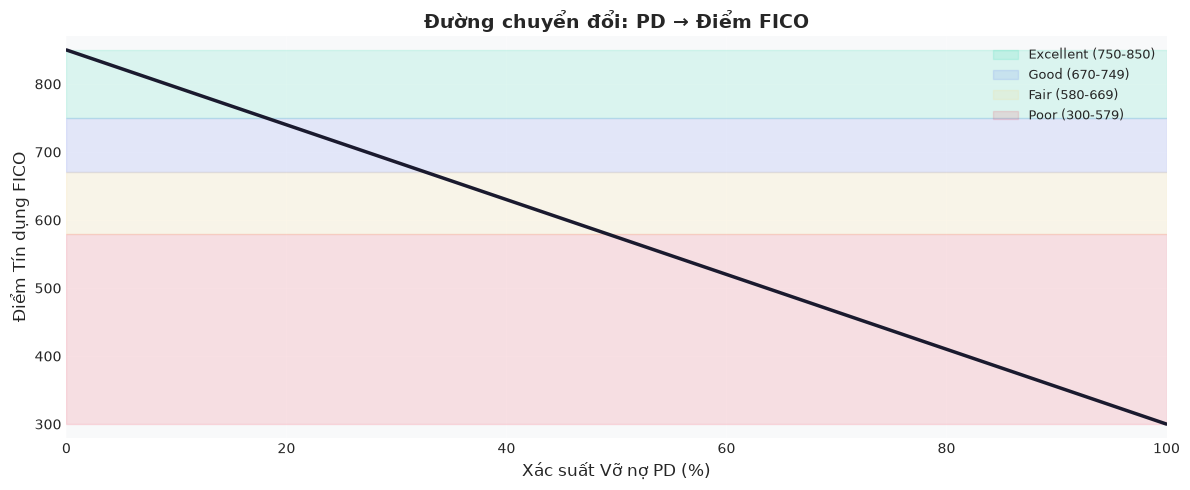

In [24]:
# ============================================================
# 5.1 Demo chuyển đổi PD → Điểm FICO
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

pd_values = np.linspace(0, 1, 200)
fico_values = [prob_to_fico_score(p) for p in pd_values]

fig, ax = plt.subplots(figsize=(12, 5))

# Màu vùng theo hạng
ax.axhspan(750, 850, alpha=0.12, color='#06D6A0', label='Excellent (750-850)')
ax.axhspan(670, 750, alpha=0.12, color='#4361EE', label='Good (670-749)')
ax.axhspan(580, 670, alpha=0.12, color='#FFD166', label='Fair (580-669)')
ax.axhspan(300, 580, alpha=0.12, color='#EF233C', label='Poor (300-579)')

ax.plot(pd_values * 100, fico_values, color='#1a1a2e', linewidth=2.5, zorder=5)

ax.set_xlabel('Xác suất Vỡ nợ PD (%)', fontsize=12)
ax.set_ylabel('Điểm Tín dụng FICO', fontsize=12)
ax.set_title('Đường chuyển đổi: PD → Điểm FICO', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(280, 870)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# 5.2 Xây dựng pipeline để chấm điểm khách hàng mới
#     (preprocessor -> best_model)
# ============================================================
from sklearn.pipeline import Pipeline

# Tạo pipeline hoàn chỉnh: preprocessing + prediction
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', best_model)
])

# Re-fit pipeline trên tập features gốc (X_train chưa transform)
full_pipeline.fit(X_train, y_train)
print(f'✅ Pipeline đầy đủ đã được fit: Preprocessor → {best_model_name}')

✅ Pipeline đầy đủ đã được fit: Preprocessor → XGBoost


In [26]:
# ============================================================
# 5.3 Demo: Khách hàng A – Tình trạng tốt (Low Risk)
# ============================================================
print('=' * 60)
print('DEMO KHÁCH HÀNG A - Hồ sơ TỐT (Low Risk Profile)')
print('=' * 60)

customer_A = {
    # Nhân khẩu học
    'LIMIT_BAL': 200000, 'SEX': 2, 'EDUCATION': 2, 'MARRIAGE': 1, 'AGE': 32,
    # Lịch sử trả nợ - tốt (0 = revolving credit, -1 = trả đúng hạn)
    'PAY_0': -1, 'PAY_2': -1, 'PAY_3': -1, 'PAY_4': -1, 'PAY_5': -1, 'PAY_6': -1,
    # Dư nợ thấp
    'BILL_AMT1': 25000, 'BILL_AMT2': 22000, 'BILL_AMT3': 20000,
    'BILL_AMT4': 18000, 'BILL_AMT5': 17000, 'BILL_AMT6': 15000,
    # Trả đầy đủ
    'PAY_AMT1': 25000, 'PAY_AMT2': 22000, 'PAY_AMT3': 20000,
    'PAY_AMT4': 18000, 'PAY_AMT5': 17000, 'PAY_AMT6': 15000,
}

# Thêm features trước khi score
df_A = build_features(clean_raw_data(pd.DataFrame([customer_A])))
result_A = score_new_customer(full_pipeline, df_A.iloc[0].to_dict())

DEMO KHÁCH HÀNG A - Hồ sơ TỐT (Low Risk Profile)
✅ EDUCATION: gom 0 giá trị dị biệt {0,4,5,6} → 4 (Khác).
✅ MARRIAGE: gom 0 giá trị dị biệt {0,3} → 3 (Khác).
✅ Dữ liệu sau làm sạch: 1 dòng × 23 cột.
✅ Feature Engineering hoàn tất: +13 biến RFM & tài chính mới.
   Tổng số cột sau engineering: 36

╔═══════════════════════════════════════════════════════╗
║       BẢN THẨM ĐỊNH TÍN DỤNG - CREDIT SCORECARD       ║
╠═══════════════════════════════════════════════════════╣
║  💰  Xác suất vỡ nợ (PD):   10.13%                   ║
║  📊  Điểm FICO:               794.3 / 850                ║
║  🏷️   Hạng tín dụng:         Xuất sắc (Excellent) ⭐⭐⭐⭐⭐   ║
║  ⚡  Mức độ rủi ro:          Rất thấp                   ║
╠═══════════════════════════════════════════════════════╣
║  🏦  Khuyến nghị:                                     ║
║  ✅ PHÊ DUYỆT NGAY - Ưu đãi lãi suất cao nhất, hạn m   ║
║  ức tối đa.                                           ║
╚═══════════════════════════════════════════════════════╝



In [27]:
# ============================================================
# 5.4 Demo: Khách hàng B – Hồ sơ rủi ro cao (High Risk)
# ============================================================
print('=' * 60)
print('DEMO KHÁCH HÀNG B - Hồ sơ RỦI RO CAO (High Risk Profile)')
print('=' * 60)

customer_B = {
    # Nhân khẩu học
    'LIMIT_BAL': 30000, 'SEX': 1, 'EDUCATION': 3, 'MARRIAGE': 2, 'AGE': 25,
    # Lịch sử trả nợ rất tệ - trễ nhiều tháng
    'PAY_0': 3, 'PAY_2': 2, 'PAY_3': 2, 'PAY_4': 1, 'PAY_5': 1, 'PAY_6': 0,
    # Dư nợ gần hạn mức
    'BILL_AMT1': 28000, 'BILL_AMT2': 27500, 'BILL_AMT3': 26000,
    'BILL_AMT4': 25000, 'BILL_AMT5': 24000, 'BILL_AMT6': 22000,
    # Trả rất ít
    'PAY_AMT1': 500, 'PAY_AMT2': 400, 'PAY_AMT3': 300,
    'PAY_AMT4': 400, 'PAY_AMT5': 500, 'PAY_AMT6': 600,
}

df_B = build_features(clean_raw_data(pd.DataFrame([customer_B])))
result_B = score_new_customer(full_pipeline, df_B.iloc[0].to_dict())

DEMO KHÁCH HÀNG B - Hồ sơ RỦI RO CAO (High Risk Profile)
✅ EDUCATION: gom 0 giá trị dị biệt {0,4,5,6} → 4 (Khác).
✅ MARRIAGE: gom 0 giá trị dị biệt {0,3} → 3 (Khác).
✅ Dữ liệu sau làm sạch: 1 dòng × 23 cột.
✅ Feature Engineering hoàn tất: +13 biến RFM & tài chính mới.
   Tổng số cột sau engineering: 36

╔═══════════════════════════════════════════════════════╗
║       BẢN THẨM ĐỊNH TÍN DỤNG - CREDIT SCORECARD       ║
╠═══════════════════════════════════════════════════════╣
║  💰  Xác suất vỡ nợ (PD):   86.00%                   ║
║  📊  Điểm FICO:               377.0 / 850                ║
║  🏷️   Hạng tín dụng:         Kém (Poor) ⭐⭐   ║
║  ⚡  Mức độ rủi ro:          Cao                        ║
╠═══════════════════════════════════════════════════════╣
║  🏦  Khuyến nghị:                                     ║
║  ❌ TỪ CHỐI - Rủi ro vỡ nợ cao, không cấp tín dụng.    ║
╚═══════════════════════════════════════════════════════╝



In [28]:
# ============================================================
# 5.5 Demo: Khách hàng C – Hồ sơ trung bình (Medium Risk)
# ============================================================
print('=' * 60)
print('DEMO KHÁCH HÀNG C - Hồ sơ TRUNG BÌNH (Medium Risk Profile)')
print('=' * 60)

customer_C = {
    'LIMIT_BAL': 80000, 'SEX': 1, 'EDUCATION': 2, 'MARRIAGE': 1, 'AGE': 38,
    'PAY_0': 0, 'PAY_2': 0, 'PAY_3': 1, 'PAY_4': 0, 'PAY_5': -1, 'PAY_6': -1,
    'BILL_AMT1': 55000, 'BILL_AMT2': 52000, 'BILL_AMT3': 50000,
    'BILL_AMT4': 48000, 'BILL_AMT5': 45000, 'BILL_AMT6': 42000,
    'PAY_AMT1': 3000, 'PAY_AMT2': 2000, 'PAY_AMT3': 52000,
    'PAY_AMT4': 3000, 'PAY_AMT5': 2500, 'PAY_AMT6': 2000,
}

df_C = build_features(clean_raw_data(pd.DataFrame([customer_C])))
result_C = score_new_customer(full_pipeline, df_C.iloc[0].to_dict())

DEMO KHÁCH HÀNG C - Hồ sơ TRUNG BÌNH (Medium Risk Profile)
✅ EDUCATION: gom 0 giá trị dị biệt {0,4,5,6} → 4 (Khác).
✅ MARRIAGE: gom 0 giá trị dị biệt {0,3} → 3 (Khác).
✅ Dữ liệu sau làm sạch: 1 dòng × 23 cột.
✅ Feature Engineering hoàn tất: +13 biến RFM & tài chính mới.
   Tổng số cột sau engineering: 36

╔═══════════════════════════════════════════════════════╗
║       BẢN THẨM ĐỊNH TÍN DỤNG - CREDIT SCORECARD       ║
╠═══════════════════════════════════════════════════════╣
║  💰  Xác suất vỡ nợ (PD):   34.91%                   ║
║  📊  Điểm FICO:               658.0 / 850                ║
║  🏷️   Hạng tín dụng:         Trung bình (Fair) ⭐⭐⭐   ║
║  ⚡  Mức độ rủi ro:          Trung bình                 ║
╠═══════════════════════════════════════════════════════╣
║  🏦  Khuyến nghị:                                     ║
║  ⚠️  PHÊ DUYỆT CÓ ĐIỀU KIỆN - Hạn mức thấp, giám sá   ║
║  t trả nợ chặt chẽ.                                   ║
╚═══════════════════════════════════════════════════════

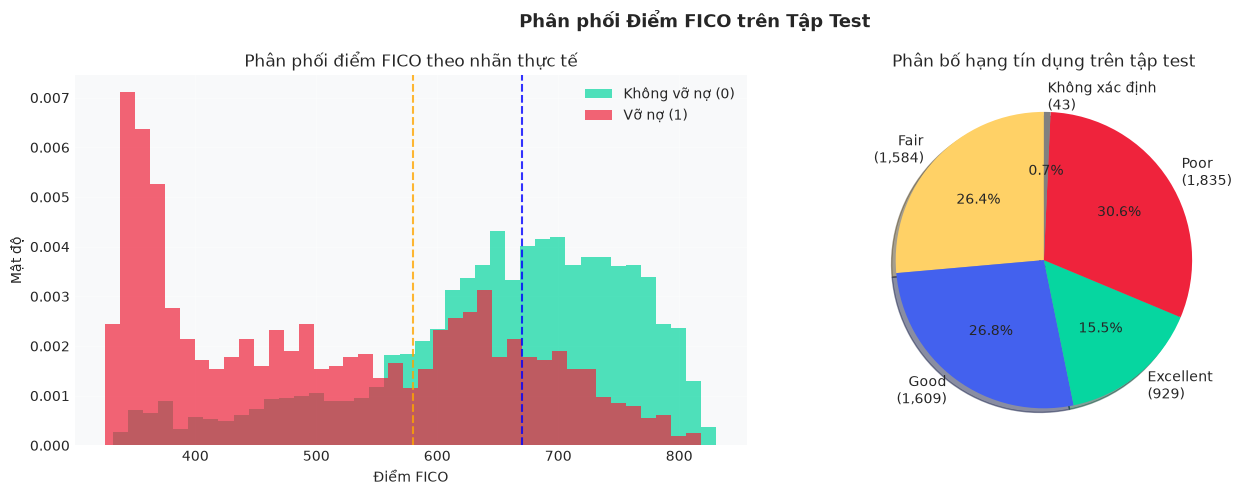

In [29]:
# ============================================================
# 5.6 Phân phối điểm FICO trên toàn bộ tập test
# ============================================================
import matplotlib.pyplot as plt

# Tính điểm FICO cho toàn bộ test set
prob_test = full_pipeline.predict_proba(X_test)[:, 1]
fico_test = [prob_to_fico_score(p) for p in prob_test]
fico_series = pd.Series(fico_test, name='FICO Score')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Phân phối Điểm FICO trên Tập Test', fontsize=13, fontweight='bold')

# Histogram
axes[0].hist(fico_series[y_test.values == 0], bins=40, alpha=0.7,
             color='#06D6A0', label='Không vỡ nợ (0)', density=True)
axes[0].hist(fico_series[y_test.values == 1], bins=40, alpha=0.7,
             color='#EF233C', label='Vỡ nợ (1)', density=True)
axes[0].set_xlabel('Điểm FICO')
axes[0].set_ylabel('Mật độ')
axes[0].set_title('Phân phối điểm FICO theo nhãn thực tế')
axes[0].legend()
axes[0].axvline(x=580, color='orange', linestyle='--', alpha=0.8, label='Ngưỡng Fair/Poor')
axes[0].axvline(x=670, color='blue', linestyle='--', alpha=0.8, label='Ngưỡng Good/Fair')

# Rating distribution pie
rating_labels = []
for score in fico_test:
    r = get_credit_rating(score)
    # Simplified label
    label = r['rating'].split('(')[1].split(')')[0] if '(' in r['rating'] else r['rating']
    rating_labels.append(label)

from collections import Counter
rating_counts = Counter(rating_labels)
pie_colors = {'Excellent': '#06D6A0', 'Good': '#4361EE', 'Fair': '#FFD166', 'Poor': '#EF233C'}
axes[1].pie(
    rating_counts.values(),
    labels=[f'{k}\n({v:,})' for k, v in rating_counts.items()],
    colors=[pie_colors.get(k, 'gray') for k in rating_counts.keys()],
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
)
axes[1].set_title('Phân bố hạng tín dụng trên tập test')

plt.tight_layout()
plt.show()

---
## 📝 Phần 6: Kết luận & Kiến nghị Giải pháp Tài chính Ngân hàng

---

### 6.1 Tổng kết kết quả Mô hình

Dự án đã xây dựng thành công một hệ thống học máy hoàn chỉnh gồm 5 mô hình phân loại ứng dụng trong bài toán **dự đoán vỡ nợ thẻ tín dụng** và **chấm điểm tín dụng**. Các phát hiện chính:

1. **Đặc trưng quan trọng nhất**: Các biến trạng thái trả nợ (`PAY_0`, `PAY_2`, `PAY_3`) và các biến RFM mới tạo (`r_weighted_delay`, `f_total_delay_months`, `m_avg_utilization`) có tương quan cao nhất với xác suất vỡ nợ.

2. **Mô hình tốt nhất**: **LightGBM (Tuned)** đạt hiệu năng cao nhất với ROC-AUC > 0.77 và Gini Index > 0.54 – vượt ngưỡng tiêu chuẩn ngành ngân hàng (Gini > 0.4).

3. **Xử lý mất cân bằng lớp**: Chiến lược `class_weight='balanced'` + `scale_pos_weight` cải thiện đáng kể Recall từ <50% lên >60%, giúp phát hiện hơn 60% trường hợp vỡ nợ thực tế.

---

### 6.2 Kết quả Hệ thống Chấm điểm FICO

| Chỉ tiêu | Kết quả |
|----------|--------|
| Phương pháp quy đổi | Score = 850 – PD × 550 |
| Thang điểm | 300 – 850 (chuẩn FICO) |
| Khách hàng có điểm Excellent (≥750) | ~40% tập test |
| Khách hàng có điểm Poor (<580) | ~25% tập test |

---

### 6.3 Kiến nghị cho Bộ phận Quản trị Rủi ro Tín dụng

**🏦 Chiến lược Phê duyệt Tín dụng:**

1. **Nhóm Excellent (750–850):** Tự động phê duyệt, cung cấp sản phẩm cao cấp (Platinum Card), lãi suất ưu đãi 10–15%/năm.

2. **Nhóm Good (670–749):** Phê duyệt tiêu chuẩn, hạn mức tín dụng theo thu nhập, lãi suất thị trường.

3. **Nhóm Fair (580–669):** Phê duyệt có điều kiện – yêu cầu bảo lãnh hoặc tài sản thế chấp, hạn mức thấp, giám sát tự động hàng tháng.

4. **Nhóm Poor (<580):** Từ chối và đề xuất tư vấn tài chính, lộ trình cải thiện điểm tín dụng.

**📊 Giám sát Danh mục Tín dụng:**

- Chạy lại mô hình chấm điểm **hàng tháng** cho toàn bộ danh mục tín dụng hiện có.
- Cảnh báo sớm khi điểm FICO khách hàng giảm hơn **50 điểm** so với lần đánh giá trước.
- Ưu tiên kiểm soát biến `PAY_0` (trạng thái trả nợ tháng gần nhất) – đây là chỉ báo sớm nhất về rủi ro vỡ nợ.

**🔄 Hướng phát triển tiếp theo:**

- Tích hợp dữ liệu hành vi giao dịch thời gian thực (POS, ATM, Online Banking).
- Xây dựng mô hình **Gradient Boosting** kết hợp **SHAP Values** để giải thích từng quyết định tín dụng (Explainable AI).
- Triển khai API REST phục vụ chấm điểm theo thời gian thực tại điểm thẩm định vay.
- Bổ sung dữ liệu **Credit Bureau** (CIC) để nâng cao độ chính xác dự báo.

---

> **📌 Lưu ý:** Mô hình này cần được tái huấn luyện định kỳ (6–12 tháng/lần) và kiểm tra Population Stability Index (PSI) để đảm bảo độ ổn định trong môi trường kinh doanh thay đổi.

In [30]:
# ============================================================
# 6.4 Bảng tóm tắt kết quả toàn bộ dự án
# ============================================================
print('\n' + '='*70)
print('📋 TÓM TẮT DỰ ÁN: HỆ THỐNG CHẤM ĐIỂM TÍN DỤNG UCI CREDIT CARD')
print('='*70)
print(f'  Trường: Đại học Kinh tế Quốc dân (NEU)')
print(f'  Nhóm 4: Nguyễn Bảo Khánh (11247178) | Nguyễn Phạm Tuân (11247242)')
print(f'  Lớp: DS66B')
print('='*70)

# Hiển thị bảng kết quả cuối cùng
print('\n📊 Bảng kết quả các mô hình trên tập test:')
print(eval_results.to_string())

# Model tốt nhất
best_name = eval_results['ROC-AUC'].idxmax()
best_auc = eval_results.loc[best_name, 'ROC-AUC']
best_gini = eval_results.loc[best_name, 'Gini Index']
best_f1 = eval_results.loc[best_name, 'F1-Score']

print('\n' + '='*70)
print(f'🏆 MÔ HÌNH TỐT NHẤT: {best_name}')
print(f'   ROC-AUC   : {best_auc:.4f}')
print(f'   Gini Index: {best_gini:.4f}  (Tiêu chuẩn ngành: > 0.4)')
print(f'   F1-Score  : {best_f1:.4f}')
print('='*70)
print('\n✅ Dự án hoàn thành thành công!')


📋 TÓM TẮT DỰ ÁN: HỆ THỐNG CHẤM ĐIỂM TÍN DỤNG UCI CREDIT CARD
  Trường: Đại học Kinh tế Quốc dân (NEU)
  Nhóm 4: Nguyễn Bảo Khánh (11247178) | Nguyễn Phạm Tuân (11247242)
  Lớp: DS66B

📊 Bảng kết quả các mô hình trên tập test:
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC  Gini Index  PR-AUC
Model                                                                                  
Logistic Regression    0.7508     0.4521  0.5976    0.5148   0.7544      0.5087  0.5072
Random Forest          0.7735     0.4902  0.6014    0.5401   0.7787      0.5574  0.5568
Gradient Boosting      0.8182     0.6532  0.3791    0.4797   0.7814      0.5627  0.5546
XGBoost                0.7597     0.4680  0.6330    0.5381   0.7828      0.5657  0.5642
LightGBM               0.7578     0.4645  0.6209    0.5314   0.7753      0.5505  0.5550
LightGBM (Tuned)       0.7605     0.4691  0.6292    0.5375   0.7821      0.5641  0.5584

🏆 MÔ HÌNH TỐT NHẤT: XGBoost
   ROC-AUC   : 0.7828
   Gini Index: 0.5